# M1-INF4 — Python Workshop for Data Analysis
## Session 5 — Data Integration Case Study

### A retail decision supported by reliable data
You are a small analytics team working for **Campus Tech**, a fictional retailer of computer accessories and equipment. The manager wants to compare stores before deciding where to investigate further.

> “The store with the highest total sales is our best-performing store. We should copy its approach everywhere.”

**Your mission:** integrate three sources, assess this claim and deliver an evidence-based recommendation.

This is a synthesis project. Use the pandas and Matplotlib techniques from Sessions 1–4. No new library or advanced modelling is required.

**All data are synthetic. Some records deliberately contain quality issues for training.** Findings describe this supplied sample, not a real company.

### What the data represent
The intended scope is **1–28 April 2025 inclusive**. This is an extract of completed orders, **not a complete record of all activity**. Coverage can differ between stores. A day absent from the extract is not evidence of zero sales or store closure.

| File | One row represents | Expected key | Purpose |
|---|---|---|---|
| `case_sales.csv` | One completed order for one product, possibly several units | `order_id` | Recorded quantity and unit selling price |
| `case_stores.csv` | One store | `store_id` | Store name, city and format |
| `case_products.csv` | One product | `product_id` | Product name and category |

Each order concerns **one product only**, so one valid order row is one order, not a line in a multi-product basket. The price is the final selling price per unit in EUR, after discounts and excluding VAT. Returns and cancellations are outside this extract.

Revenue per order = quantity × unit selling price. **Revenue is not profit**: costs, staffing, opening hours and customer traffic are unavailable.

The reference files should have unique keys, but this must be checked. Repeated store or product IDs in the sales file are normal.

### Data dictionary
| Field | Meaning and rule |
|---|---|
| `order_id` | Order identifier, required and unique after removing exact repeated records |
| `date` | Order date, expected format `YYYY-MM-DD`, within the study window |
| `store_id`, `product_id` | Reference keys; trim spaces and normalise case before joining |
| `quantity` | Positive whole number of units |
| `unit_price_eur` | Positive numeric unit price; a decimal comma may occur |
| `store_name`, `city`, `store_format` | Store attributes; “Small”/“Large” describes format, not observed floor area |
| `product_name`, `category` | Product attributes |

**Quality policy:** keep raw objects unchanged. Remove exact duplicate rows with an audit count. Convert invalid dates/numbers to missing values. Keep invalid or unmatched records in review tables, without inventing replacements. Do not remove a large but valid order simply because it is unusual. If duplicate reference keys disagree, investigate rather than arbitrarily keeping the first row.

### Files and group deliverable
Place this notebook in `notebooks/` and the three CSV files in the neighbouring `data/` folder. You may also put the CSV files beside the notebook.

Submit one completed notebook per group, the exported summary tables and three labelled figures. Record group members below. Divide the work, then review the entire analysis together: **every member must be able to explain the data unit, cleaning choices, joins and conclusions**.

Group members: *À COMPLÉTER — Nom Prénom (×4) — Groupe n° ...*

The sections below form one continuous analysis. Each checkpoint is a review of your own results, not a separate dataset.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path('../data'), Path('data'), Path('.')]
DATA_DIR = next((p for p in candidates if all((p / f).exists() for f in
    ['case_sales.csv', 'case_stores.csv', 'case_products.csv'])), None)
if DATA_DIR is None:
    raise FileNotFoundError('Place the three case_*.csv files in data/ or beside this notebook.')
OUT_DIR = Path('case_study_outputs')
OUT_DIR.mkdir(exist_ok=True)

sales_raw = pd.read_csv(DATA_DIR / 'case_sales.csv', dtype='string')
stores_raw = pd.read_csv(DATA_DIR / 'case_stores.csv', dtype='string')
products_raw = pd.read_csv(DATA_DIR / 'case_products.csv', dtype='string')
for name, frame in [('Sales', sales_raw), ('Stores', stores_raw), ('Products', products_raw)]:
    print(name, frame.shape)
    display(frame.head())


import hashlib
from IPython.display import Markdown
RAW_FILES = ['case_sales.csv', 'case_stores.csv', 'case_products.csv']
RAW_HASHES = {f: hashlib.sha256((DATA_DIR / f).read_bytes()).hexdigest() for f in RAW_FILES}
STUDY_START, STUDY_END = pd.Timestamp('2025-04-01'), pd.Timestamp('2025-04-28')
STUDY_DAYS = pd.date_range(STUDY_START, STUDY_END, freq='D')
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

Sales (252, 6)


,order_id,date,store_id,product_id,quantity,unit_price_eur
0,O0001,2025-04-21,s1,P02,3,19.90
1,O0002,2025-04-14,S1,p02,2,39.90
2,O0003,2025-04-14,S1,P04,1,"179,00"
3,O0004,2025-04-31,S1,P03,1,179.00
4,O0005,2025-04-09,S1,P02,two,19.90


Stores (4, 4)


,store_id,store_name,city,store_format
0,S1,Paris Centre,Paris,Small
1,S2,Paris Est,Paris,Large
2,S3,Lyon Centre,Lyon,Small
3,S4,Lille Centre,Lille,Large


Products (7, 3)


,product_id,product_name,category
0,P01,Keyboard,Accessories
1,P02,Mouse,Accessories
2,P03,Monitor,Screens
3,P04,Headset,Audio
4,P05,Webcam,Video


## 1. Understand and audit the sources
1. Report row and column counts, missing values and exact duplicate counts for each source.
2. Check the expected keys. Explain why repeated `store_id` values are acceptable in sales but potentially dangerous in stores.
3. Write the observation unit and the proposed join keys before joining anything.

**Checkpoint:** your audit should distinguish missing data, repeated records and normal repeated foreign keys.

In [2]:

def norm_id(s, upper=True):
    """Identifiant normalisé : espaces retirés, casse unifiée, chaîne vide -> manquant."""
    out = s.str.strip()
    if upper:
        out = out.str.upper()
    return out.mask((out == '').fillna(False))

def blank_to_na(df):
    """Copie dans laquelle espaces seuls / chaînes vides comptent comme manquants (audit uniquement)."""
    out = df.copy()
    for c in out.columns:
        out[c] = norm_id(out[c], upper=False)
    return out

sources = {'sales': sales_raw, 'stores': stores_raw, 'products': products_raw}
keys = {'sales': 'order_id', 'stores': 'store_id', 'products': 'product_id'}


audit_overview = pd.DataFrame([{
    'source': n, 'rows': len(f), 'columns': f.shape[1],
    'missing_cells': int(blank_to_na(f).isna().sum().sum()),
    'exact_duplicate_rows': int(f.duplicated().sum())} for n, f in sources.items()])
display(audit_overview)

for n, f in sources.items():
    miss = blank_to_na(f).isna().sum()
    print(f'\nValeurs manquantes par colonne — {n}')
    display(miss[miss > 0].rename('missing').to_frame() if (miss > 0).any() else 'aucune')


rows = []
for n, f in sources.items():
    k = norm_id(f[keys[n]])
    k_after = norm_id(f.drop_duplicates()[keys[n]]).dropna()
    rows.append({'source': n, 'key': keys[n],
                 'missing_keys': int(k.isna().sum()),
                 'rows_sharing_a_key (raw)': int(k.dropna().duplicated(keep=False).sum()),
                 'of which exact duplicates removed': int(f.duplicated().sum()),
                 'repeated keys left after exact dedup': int(k_after.duplicated(keep=False).sum())})
key_audit = pd.DataFrame(rows)
display(key_audit)


fk = pd.DataFrame({
    'distinct_values (raw text)': [sales_raw['store_id'].nunique(), sales_raw['product_id'].nunique()],
    'distinct_values (normalised)': [norm_id(sales_raw['store_id']).nunique(), norm_id(sales_raw['product_id']).nunique()],
    'mean_orders_per_key': [sales_raw['store_id'].notna().sum() / norm_id(sales_raw['store_id']).nunique(),
                            sales_raw['product_id'].notna().sum() / norm_id(sales_raw['product_id']).nunique()]},
    index=['store_id', 'product_id'])
display(fk)


display(stores_raw[['store_id', 'store_name', 'city', 'store_format']])
print('Catégories :', sorted(products_raw['category'].dropna().unique()))
print('Prix avec virgule décimale :', int(sales_raw['unit_price_eur'].str.contains(',', na=False).sum()))
bad_fmt = ~sales_raw['date'].str.strip().str.fullmatch(r'\d{4}-\d{2}-\d{2}').fillna(False)
print('Dates qui ne respectent pas YYYY-MM-DD :', int(bad_fmt.sum()))

,source,rows,columns,missing_cells,exact_duplicate_rows
0,sales,252,6,1,2
1,stores,4,4,0,0
2,products,7,3,0,1



Valeurs manquantes par colonne — sales


,missing
unit_price_eur,1



Valeurs manquantes par colonne — stores


'aucune'

...

'aucune'

,source,key,missing_keys,rows_sharing_a_key (raw),of which exact duplicates removed,repeated keys left after exact dedup
0,sales,order_id,0,4,2,0
1,stores,store_id,0,0,0,0
2,products,product_id,0,2,1,0


,distinct_values (raw text),distinct_values (normalised),mean_orders_per_key
store_id,6,5,50.40
product_id,8,7,36.00


,store_id,store_name,city,store_format
0,S1,Paris Centre,Paris,Small
1,S2,Paris Est,Paris,Large
2,S3,Lyon Centre,Lyon,Small
3,S4,Lille Centre,Lille,Large


Catégories : ['Accessories', 'Audio', 'Screens', 'Video']
Prix avec virgule décimale : 1
Dates qui ne respectent pas YYYY-MM-DD : 0


**Notre interprétation**

**Ce que représente une ligne.** Dans `case_sales.csv`, une ligne est **une commande terminée pour un seul produit** (plusieurs unités possibles), identifiée par `order_id`. Dans `case_stores.csv`, une ligne est **un magasin** (`store_id`) ; dans `case_products.csv`, une ligne est **un produit** (`product_id`).

**Colonnes de jointure.** `sales.store_id` → `stores.store_id` et `sales.product_id` → `products.product_id`, après suppression des espaces et mise en majuscules. Ce sont des jointures *many-to-one* : plusieurs commandes pour un même magasin ou un même produit.

**Valeurs manquantes, enregistrements répétés, clés répétées.** Une valeur manquante est une cellule vide ; nous ne la remplaçons pas et ne l'inventons pas. Un doublon exact est une ligne identique sur toutes les colonnes : c'est le même enregistrement saisi deux fois, que nous supprimons après comptage. En revanche, la répétition de `store_id` ou `product_id` dans `sales` est normale (un magasin vend de nombreuses commandes). Elle devient dangereuse dans `stores` et `products`, où une clé répétée dupliquerait chaque commande lors de la jointure et gonflerait effectifs et chiffre d'affaires ; si ces doublons se contredisent, nous ne pouvons pas choisir « le premier » sans arbitraire.

## 2. Prepare reliable tables
Create working copies. Apply the quality policy above.

1. Count and remove **exact** duplicate records in all three tables.
2. Normalise identifiers, parse dates and convert the two numeric fields. Handle decimal commas.
3. Flag missing IDs, failed conversions, non-positive prices, quantities that are not positive integers, and dates outside the study window.
4. Produce `sales_valid` and `sales_review`. Keep the rejected records and the reason flags.
5. Validate unique, non-missing reference keys and unique valid order IDs.

**Checkpoint:** input rows = exact duplicates removed + invalid rows retained for review + valid rows. Multiple reason flags can describe the same rejected row, so do not sum flags as if they were distinct rows.

In [3]:

dup_counts = {n: int(f.duplicated().sum()) for n, f in sources.items()}
sales_w = sales_raw.drop_duplicates().copy()
sales_w['source_row'] = sales_w.index + 2
print('Doublons exacts supprimés :', dup_counts)


def prepare_reference(df, key, name):
    d = df.drop_duplicates().copy()
    for c in d.columns:
        d[c] = d[c].str.strip()
    d[key] = norm_id(d[key])
    n0 = len(d)
    d = d.drop_duplicates()
    harmless = n0 - len(d)
    missing = d[key].isna()
    repeated = d[key].notna() & d[key].duplicated(keep=False)
    review = d[missing | repeated].copy()
    review['reason'] = np.where(missing[missing | repeated], 'missing_key', 'conflicting_duplicate_key')
    clean = d[~(missing | repeated)].copy()
    assert clean[key].is_unique and clean[key].notna().all()
    print(f'{name}: {len(df)} lignes brutes -> {len(clean)} valides | '
          f'répétitions inoffensives retirées: {harmless} | clés manquantes: {int(missing.sum())} | '
          f'lignes à clé contradictoire: {int(repeated.sum())}')
    return clean, review

stores_ref, stores_review = prepare_reference(stores_raw, 'store_id', 'stores')
products_ref, products_review = prepare_reference(products_raw, 'product_id', 'products')
if len(stores_review) or len(products_review):
    print('\n⚠ Clés de référence à investiguer (exclues des jointures, jamais « premier gardé ») :')
    display(pd.concat([stores_review, products_review]))
print('\nFormats de magasin :', sorted(stores_ref['store_format'].dropna().unique()))


n_id_repaired = int(((norm_id(sales_w['store_id']) != sales_w['store_id']).fillna(False) & sales_w['store_id'].notna()).sum()
                    + ((norm_id(sales_w['product_id']) != sales_w['product_id']).fillna(False) & sales_w['product_id'].notna()).sum())
sales_w['order_id'] = norm_id(sales_w['order_id'], upper=False)
sales_w['store_id'] = norm_id(sales_w['store_id'])
sales_w['product_id'] = norm_id(sales_w['product_id'])
sales_w['order_date'] = pd.to_datetime(sales_w['date'].str.strip(), format='%Y-%m-%d', errors='coerce')
n_decimal_comma = int(sales_w['unit_price_eur'].str.contains(',', na=False).sum())
sales_w['quantity_num'] = pd.to_numeric(sales_w['quantity'].str.strip().str.replace(',', '.', regex=False), errors='coerce')
sales_w['unit_price_num'] = pd.to_numeric(sales_w['unit_price_eur'].str.strip().str.replace(',', '.', regex=False), errors='coerce')
print(f'\nPrix à virgule décimale convertis (réparation de format, pas de valeur inventée) : {n_decimal_comma}')


flags = pd.DataFrame({
    'missing_order_id':      sales_w['order_id'].isna(),
    'missing_store_id':      sales_w['store_id'].isna(),
    'missing_product_id':    sales_w['product_id'].isna(),
    'invalid_date':          sales_w['order_date'].isna(),
    'date_outside_window':   sales_w['order_date'].notna() & ((sales_w['order_date'] < STUDY_START) | (sales_w['order_date'] > STUDY_END)),
    'invalid_quantity':      sales_w['quantity_num'].isna(),
    'quantity_not_pos_int':  sales_w['quantity_num'].notna() & ((sales_w['quantity_num'] <= 0) | (sales_w['quantity_num'] % 1 != 0)),
    'invalid_price':         sales_w['unit_price_num'].isna(),
    'price_not_positive':    sales_w['unit_price_num'].notna() & (sales_w['unit_price_num'] <= 0),
    'duplicate_order_id':    sales_w['order_id'].notna() & sales_w['order_id'].duplicated(keep=False),
})
is_invalid = flags.any(axis=1)


sales_review = sales_w[is_invalid].copy()
sales_review['reasons'] = flags[is_invalid].apply(lambda r: '; '.join(r.index[r.values]), axis=1)
sales_review = pd.concat([sales_review, flags[is_invalid]], axis=1)

sales_valid = (sales_w[~is_invalid]
               .rename(columns={'order_date': 'date_parsed'})
               .assign(date=lambda d: d['date_parsed'],
                       quantity=lambda d: d['quantity_num'].astype('int64'),
                       unit_price_eur=lambda d: d['unit_price_num'].astype('float64'))
               [['order_id', 'date', 'store_id', 'product_id', 'quantity', 'unit_price_eur']]
               .reset_index(drop=True))


assert sales_valid['order_id'].is_unique and sales_valid['order_id'].notna().all()
assert sales_valid['date'].between(STUDY_START, STUDY_END).all()
assert (sales_valid['quantity'] > 0).all() and (sales_valid['unit_price_eur'] > 0).all()
assert len(sales_raw) == dup_counts['sales'] + len(sales_review) + len(sales_valid)
print(f'\nCHECKPOINT : {len(sales_raw)} lignes brutes = {dup_counts["sales"]} doublons exacts '
      f'+ {len(sales_review)} lignes en revue + {len(sales_valid)} lignes valides')

flag_counts = flags.sum().rename('rows_flagged').to_frame()
flag_counts = flag_counts[flag_counts.rows_flagged > 0]
print('\nLignes concernées par règle (une ligne peut cumuler plusieurs règles : NE PAS additionner) :')
display(flag_counts)
display(sales_review.head(10))

Doublons exacts supprimés : {'sales': 2, 'stores': 0, 'products': 1}
stores: 4 lignes brutes -> 4 valides | répétitions inoffensives retirées: 0 | clés manquantes: 0 | lignes à clé contradictoire: 0
products: 7 lignes brutes -> 6 valides | répétitions inoffensives retirées: 0 | clés manquantes: 0 | lignes à clé contradictoire: 0

Formats de magasin : ['Large', 'Small']

Prix à virgule décimale convertis (réparation de format, pas de valeur inventée) : 1

CHECKPOINT : 252 lignes brutes = 2 doublons exacts + 7 lignes en revue + 243 lignes valides

Lignes concernées par règle (une ligne peut cumuler plusieurs règles : NE PAS additionner) :


,rows_flagged
invalid_date,1
date_outside_window,1
invalid_quantity,1
quantity_not_pos_int,2
invalid_price,1
price_not_positive,1


,order_id,date,store_id,product_id,quantity,unit_price_eur,source_row,order_date,quantity_num,unit_price_num,...,missing_order_id,missing_store_id,missing_product_id,invalid_date,date_outside_window,invalid_quantity,quantity_not_pos_int,invalid_price,price_not_positive,duplicate_order_id
3,O0004,2025-04-31,S1,P03,1,179.00,5,NaT,1.00,179.00,...,False,False,False,True,False,False,False,False,False,False
4,O0005,2025-04-09,S1,P02,two,19.90,6,2025-04-09,<NA>,19.90,...,False,False,False,False,False,True,False,False,False,False
5,O0006,2025-04-04,S1,P06,3,<NA>,7,2025-04-04,3.00,<NA>,...,False,False,False,False,False,False,False,True,False,False
6,O0007,2025-04-12,S1,P06,-1,29.90,8,2025-04-12,-1.00,29.90,...,False,False,False,False,False,False,True,False,False,False
7,O0008,2025-04-07,S1,P02,2,-19.90,9,2025-04-07,2.00,-19.90,...,False,False,False,False,False,False,False,False,True,False
8,O0009,2025-04-13,S1,P02,1.5,19.90,10,2025-04-13,1.50,19.90,...,False,False,False,False,False,False,True,False,False,False
11,O0012,2025-05-02,S1,P01,2,39.90,13,2025-05-02,2.00,39.90,...,False,False,False,False,True,False,False,False,False,False


In [4]:
_labels = {'missing_order_id': 'identifiant de commande manquant', 'missing_store_id': 'identifiant magasin manquant',
           'missing_product_id': 'identifiant produit manquant', 'invalid_date': 'date illisible', 'date_outside_window': 'date hors du 1–28 avril 2025',
           'invalid_quantity': 'quantité illisible', 'quantity_not_pos_int': 'quantité nulle, négative ou non entière',
           'invalid_price': 'prix illisible', 'price_not_positive': 'prix nul ou négatif', 'duplicate_order_id': 'identifiant de commande partagé par plusieurs lignes différentes'}
_rev_sv = sales_valid['quantity'] * sales_valid['unit_price_eur']
_biggest = sales_valid.loc[_rev_sv.idxmax()]
_rules = '\n'.join(f"  - {_labels[k]} : {int(v)} ligne(s)" for k, v in flags.sum().items() if v > 0) or '  - aucune règle déclenchée'
if len(stores_review) or len(products_review):
    _ref = (f"{len(stores_review)} ligne(s) de `stores` et {len(products_review)} ligne(s) de `products` ont une clé manquante ou répétée avec des contenus différents : "
            "nous les avons exclues des jointures et signalées, au lieu de garder arbitrairement la première.")
else:
    _ref = "Aucune clé de référence n'est manquante ni répétée avec des contenus contradictoires : les tables `stores` et `products` ont des clés uniques."
display(Markdown(f"**Notre interprétation**\n\n"
    f"**Supprimé.** Nous retirons les doublons exacts : {dup_counts['sales']} dans `sales`, {dup_counts['stores']} dans `stores`, {dup_counts['products']} dans `products`. "
    f"Garder un enregistrement répété compterait deux fois le même chiffre d'affaires.\n\n"
    f"**Réparé (écriture seulement).** {n_id_repaired} identifiant(s) magasin ou produit normalisé(s) (espaces, casse) et {n_decimal_comma} prix écrit(s) avec une virgule décimale ont été convertis. "
    f"Nous changeons la forme, jamais l'information.\n\n"
    f"**Mis de côté dans `sales_review` ({len(sales_review)} lignes).** Nous n'imputons rien : un prix ou une quantité de remplacement serait une invention. "
    f"Raisons (une ligne peut en cumuler plusieurs, donc ces comptes ne s'additionnent pas) :\n\n{_rules}\n\n"
    f"**Conservé dans l'analyse.** Les {len(sales_valid)} commandes valides, y compris les plus inhabituelles : la plus grande vaut {_rev_sv.max():,.0f} EUR "
    f"({int(_biggest['quantity'])} × {_biggest['unit_price_eur']:,.2f} EUR). Une valeur extrême n'est pas une erreur ; nous la laissons visible dans le boxplot.\n\n"
    f"**Références.** {_ref}"))

**Notre interprétation**

**Supprimé.** Nous retirons les doublons exacts : 2 dans `sales`, 0 dans `stores`, 1 dans `products`. Garder un enregistrement répété compterait deux fois le même chiffre d'affaires.

**Réparé (écriture seulement).** 2 identifiant(s) magasin ou produit normalisé(s) (espaces, casse) et 1 prix écrit(s) avec une virgule décimale ont été convertis. Nous changeons la forme, jamais l'information.

**Mis de côté dans `sales_review` (7 lignes).** Nous n'imputons rien : un prix ou une quantité de remplacement serait une invention. Raisons (une ligne peut en cumuler plusieurs, donc ces comptes ne s'additionnent pas) :

  - date illisible : 1 ligne(s)
  - date hors du 1–28 avril 2025 : 1 ligne(s)
  - quantité illisible : 1 ligne(s)
  - quantité nulle, négative ou non entière : 2 ligne(s)
  - prix illisible : 1 ligne(s)
  - prix nul ou négatif : 1 ligne(s)

**Conservé dans l'analyse.** Les 243 commandes valides, y compris les plus inhabituelles : la plus grande vaut 537 EUR (3 × 179.00 EUR). Une valeur extrême n'est pas une erreur ; nous la laissons visible dans le boxplot.

**Références.** Aucune clé de référence n'est manquante ni répétée avec des contenus contradictoires : les tables `stores` et `products` ont des clés uniques.

## 3. Integrate and reconcile
1. Join `sales_valid` to stores with a **left join**, `validate="many_to_one"` and an indicator. Inspect unmatched keys.
2. Join that result to products with the same controls. Use a different indicator name, or rename/remove the first indicator before the second join.
3. Check that neither join changes the row count.
4. Keep orders missing either reference in `integration_review`. Create `analysis` using orders matched to **both** references.
5. Present a reconciliation table from raw input to the final analytical population.

**Checkpoint:** never interpret an unknown product as zero revenue, and never allow a duplicated reference key to multiply orders. State how many orders the analysis excludes.

In [5]:
n_valid = len(sales_valid)


j1 = sales_valid.merge(stores_ref, on='store_id', how='left', validate='many_to_one', indicator='store_merge')
assert len(j1) == n_valid, 'La jointure stores a modifié le nombre de lignes'


j2 = j1.merge(products_ref, on='product_id', how='left', validate='many_to_one', indicator='product_merge')
assert len(j2) == n_valid, 'La jointure products a modifié le nombre de lignes'

store_ok = j2['store_merge'].eq('both')
product_ok = j2['product_merge'].eq('both')


unmatched_stores = j2.loc[~store_ok, 'store_id'].value_counts().rename('orders').rename_axis('unmatched_store_id')
unmatched_products = j2.loc[~product_ok, 'product_id'].value_counts().rename('orders').rename_axis('unmatched_product_id')
print('Clés magasin sans correspondance :'); display(unmatched_stores.to_frame())
print('Clés produit sans correspondance :'); display(unmatched_products.to_frame())
print('Effectifs : valides =', n_valid, '| après join stores =', len(j1), '| après join products =', len(j2))


conflict_stores = set(stores_review['store_id'].dropna())
conflict_products = set(products_review['product_id'].dropna())
def why(row):
    out = []
    if row['store_merge'] != 'both':
        out.append('store_key_conflicting_in_reference' if row['store_id'] in conflict_stores else 'store_id_not_in_stores')
    if row['product_merge'] != 'both':
        out.append('product_key_conflicting_in_reference' if row['product_id'] in conflict_products else 'product_id_not_in_products')
    return '; '.join(out)

integration_review = j2[~(store_ok & product_ok)].copy()
integration_review['reasons'] = integration_review.apply(why, axis=1)
analysis = (j2[store_ok & product_ok]
            .drop(columns=['store_merge', 'product_merge'])
            .reset_index(drop=True))
assert analysis['order_id'].is_unique
assert len(analysis) + len(integration_review) == n_valid


val_rev = sales_valid['quantity'] * sales_valid['unit_price_eur']
def rev(mask): return float((val_rev[mask.values]).sum())
only_store = ~store_ok & product_ok
only_prod = store_ok & ~product_ok
both_bad = ~store_ok & ~product_ok
reconciliation = pd.DataFrame([
    ('1. Lignes brutes sales',                         len(sales_raw), np.nan),
    ('2. - doublons exacts supprimés',                 -dup_counts['sales'], np.nan),
    ('3. = lignes après déduplication',                len(sales_raw) - dup_counts['sales'], np.nan),
    ('4. - lignes invalides (sales_review)',           -len(sales_review), np.nan),
    ('5. = sales_valid',                               n_valid, float(val_rev.sum())),
    ('6. - magasin inconnu seulement',                 -int(only_store.sum()), -rev(only_store)),
    ('7. - produit inconnu seulement',                 -int(only_prod.sum()), -rev(only_prod)),
    ('8. - magasin ET produit inconnus',               -int(both_bad.sum()), -rev(both_bad)),
    ('9. = analysis (appariées aux deux références)',  len(analysis), float((analysis['quantity'] * analysis['unit_price_eur']).sum())),
], columns=['step', 'orders', 'revenue_eur'])
assert reconciliation.loc[8, 'orders'] == reconciliation.loc[4, 'orders'] + reconciliation.loc[5:7, 'orders'].sum()
display(reconciliation)

excl = len(integration_review)
print(f'\nL’analyse exclut {excl} commandes valides non appariées ({excl / n_valid:.1%} des commandes valides) '
      f'et {len(sales_review)} commandes invalides ; population analysée : {len(analysis)} commandes '
      f'({len(analysis) / len(sales_raw):.1%} des lignes brutes).')
display(integration_review.head())

Clés magasin sans correspondance :


,orders
unmatched_store_id,
S99,1


Clés produit sans correspondance :


,orders
unmatched_product_id,
P99,1


Effectifs : valides = 243 | après join stores = 243 | après join products = 243


,step,orders,revenue_eur
0,1. Lignes brutes sales,252,NaN
1,2. - doublons exacts supprimés,-2,NaN
2,3. = lignes après déduplication,250,NaN
3,4. - lignes invalides (sales_review),-7,NaN
4,5. = sales_valid,243,"27,836.40"
5,6. - magasin inconnu seulement,-1,-89.70
6,7. - produit inconnu seulement,-1,-39.90
7,8. - magasin ET produit inconnus,0,-0.00
8,9. = analysis (appariées aux deux références),241,"27,706.80"



L’analyse exclut 2 commandes valides non appariées (0.8% des commandes valides) et 7 commandes invalides ; population analysée : 241 commandes (95.6% des lignes brutes).


,order_id,date,store_id,product_id,quantity,unit_price_eur,store_name,city,store_format,store_merge,product_name,category,product_merge,reasons
3,O0010,2025-04-04,S99,P06,3,29.90,<NA>,<NA>,<NA>,left_only,USB hub,Accessories,both,store_id_not_in_stores
4,O0011,2025-04-20,S1,P99,1,39.90,Paris Centre,Paris,Small,both,<NA>,<NA>,left_only,product_id_not_in_products


**Notre interprétation**

Nous commençons par des jointures à gauche pour **conserver toutes les commandes valides**, même quand la référence manque, et l'indicateur nous dit *lesquelles* n'ont pas trouvé de correspondance. Avec une jointure interne, ces commandes disparaîtraient en silence : nous ne saurions ni combien, ni pourquoi, ni quel chiffre d'affaires est concerné.

`validate="many_to_one"` fait échouer la jointure si une clé de référence est répétée ; nous ne pouvons donc pas multiplier des commandes sans nous en apercevoir, et le contrôle du nombre de lignes après chaque jointure le confirme.

Une commande dont le magasin ou le produit est inconnu **ne vaut pas zéro euro** : son chiffre d'affaires est réel mais non attribuable. Nous la gardons dans `integration_review`, le tableau de réconciliation chiffre son poids, et l'analyse se limite aux commandes appariées aux **deux** références.

## 4. Build indicators that answer the question
For each order in `analysis`, calculate `revenue_eur`.

Create `store_summary` with, for each store:
- order count and total units;
- total revenue (EUR);
- mean and median revenue per order (EUR).

Also create a revenue summary by product category and a daily revenue table for each store. Check that the totals reconcile with the order-level revenue.

Compare the store with the highest total revenue to the store with the highest mean revenue per order. Do they coincide? Explain the role of order counts and product mix.

**Important:** `quantity` counts units, not orders. Mean revenue per order = total revenue / number of orders. Round for presentation, not before aggregation. Avoid calling this a profitability or productivity ranking.

In [6]:

analysis['revenue_eur'] = analysis['quantity'] * analysis['unit_price_eur']
analysis['store_label'] = analysis['store_id'] + ' – ' + analysis['store_name']
assert (analysis['revenue_eur'] > 0).all()


store_summary = (analysis.groupby(['store_id', 'store_name', 'city', 'store_format'], as_index=False)
    .agg(orders=('order_id', 'size'), units=('quantity', 'sum'),
         total_revenue_eur=('revenue_eur', 'sum'),
         mean_revenue_per_order_eur=('revenue_eur', 'mean'),
         median_revenue_per_order_eur=('revenue_eur', 'median'),
         days_with_orders=('date', 'nunique')))
store_summary['revenue_per_observed_day_eur'] = store_summary['total_revenue_eur'] / store_summary['days_with_orders']
store_summary['share_of_total_revenue_pct'] = 100 * store_summary['total_revenue_eur'] / store_summary['total_revenue_eur'].sum()
store_summary = store_summary.sort_values('total_revenue_eur', ascending=False).reset_index(drop=True)
assert np.isclose(store_summary['mean_revenue_per_order_eur'],
                  store_summary['total_revenue_eur'] / store_summary['orders']).all()
display(store_summary.round(2))


category_summary = (analysis.groupby('category', as_index=False)
    .agg(orders=('order_id', 'size'), units=('quantity', 'sum'), total_revenue_eur=('revenue_eur', 'sum'),
         mean_revenue_per_order_eur=('revenue_eur', 'mean')))
category_summary['share_of_total_revenue_pct'] = 100 * category_summary['total_revenue_eur'] / category_summary['total_revenue_eur'].sum()
category_summary = category_summary.sort_values('total_revenue_eur', ascending=False).reset_index(drop=True)
display(category_summary.round(2))


daily_revenue = (analysis.pivot_table(index='date', columns='store_id', values='revenue_eur', aggfunc='sum')
                 .reindex(STUDY_DAYS))
daily_revenue.index.name = 'date'
display(daily_revenue.round(2).head(10))
print('Jours-magasins observés :', int(daily_revenue.notna().sum().sum()), 'sur', daily_revenue.size, 'possibles')


total_orders_level = analysis['revenue_eur'].sum()
assert np.isclose(store_summary['total_revenue_eur'].sum(), total_orders_level)
assert np.isclose(category_summary['total_revenue_eur'].sum(), total_orders_level)
assert np.isclose(daily_revenue.sum().sum(), total_orders_level)
assert store_summary['orders'].sum() == len(analysis) == category_summary['orders'].sum()
print(f'Totaux réconciliés : {total_orders_level:,.2f} EUR sur {len(analysis)} commandes '
      '(commande = magasin = catégorie = quotidien).')


top_total = store_summary.loc[store_summary['total_revenue_eur'].idxmax()]
top_mean = store_summary.loc[store_summary['mean_revenue_per_order_eur'].idxmax()]
top_orders = store_summary.loc[store_summary['orders'].idxmax()]
same_store = top_total['store_id'] == top_mean['store_id']
print(f"\nPlus fort total : {top_total['store_id']} ({top_total['total_revenue_eur']:,.0f} EUR, {int(top_total['orders'])} commandes)")
print(f"Plus forte moyenne/commande : {top_mean['store_id']} ({top_mean['mean_revenue_per_order_eur']:,.0f} EUR)")
print('Coïncident :', same_store)

,store_id,store_name,city,store_format,orders,units,total_revenue_eur,mean_revenue_per_order_eur,median_revenue_per_order_eur,days_with_orders,revenue_per_observed_day_eur,share_of_total_revenue_pct
0,S2,Paris Est,Paris,Large,70,116,"10,528.90",150.41,79.80,25,421.16,38.00
1,S1,Paris Centre,Paris,Small,91,155,"6,482.90",71.24,39.90,27,240.11,23.40
2,S4,Lille Centre,Lille,Large,30,51,"5,712.50",190.42,158.50,20,285.62,20.62
3,S3,Lyon Centre,Lyon,Small,50,86,"4,982.50",99.65,64.45,22,226.48,17.98


,category,orders,units,total_revenue_eur,mean_revenue_per_order_eur,share_of_total_revenue_pct
0,Screens,45,81,"14,499.00",322.20,52.33
1,Accessories,133,224,"6,427.60",48.33,23.20
2,Video,32,54,"3,726.00",116.44,13.45
3,Audio,31,49,"3,054.20",98.52,11.02


store_id,S1,S2,S3,S4
date,,,,
2025-04-01,69.70,675.70,239.30,258.80
2025-04-02,199.50,308.60,567.50,358.00
2025-04-03,269.00,358.00,29.90,606.00
2025-04-04,419.20,576.90,139.70,358.00
2025-04-05,269.20,954.90,266.70,167.90
2025-04-06,79.70,396.70,477.50,119.70
2025-04-07,148.70,298.60,NaN,39.80
2025-04-08,446.40,854.00,676.50,179.00
2025-04-09,69.80,NaN,NaN,208.90


Jours-magasins observés : 94 sur 112 possibles
Totaux réconciliés : 27,706.80 EUR sur 241 commandes (commande = magasin = catégorie = quotidien).

Plus fort total : S2 (10,529 EUR, 70 commandes)
Plus forte moyenne/commande : S4 (190 EUR)
Coïncident : False


In [7]:
rk_total = store_summary['total_revenue_eur'].rank(ascending=False).astype(int)
rk_mean = store_summary['mean_revenue_per_order_eur'].rank(ascending=False).astype(int)
rk_med = store_summary['median_revenue_per_order_eur'].rank(ascending=False).astype(int)
rk = pd.DataFrame({'store': store_summary['store_id'], 'rank_total': rk_total, 'rank_orders': store_summary['orders'].rank(ascending=False).astype(int),
                   'rank_mean': rk_mean, 'rank_median': rk_med})
display(rk)
verdict = ('Le même magasin domine le total et la moyenne par commande.' if same_store else
           f"Le plus fort total ({top_total['store_id']}) n'est PAS le plus fort revenu moyen par commande ({top_mean['store_id']}).")
gap = top_total['total_revenue_eur'] / store_summary['total_revenue_eur'].sum()
display(Markdown(f"""**Notre interprétation**

{verdict} {top_total['store_id']} représente {gap:.1%} du chiffre d'affaires de l'échantillon, sur {int(top_total['orders'])} commandes
({top_total['orders'] / len(analysis):.1%} des commandes) avec un revenu moyen de {top_total['mean_revenue_per_order_eur']:,.0f} EUR et médian de {top_total['median_revenue_per_order_eur']:,.0f} EUR.
Le total = (nombre de commandes) × (revenu moyen par commande) : un magasin peut donc être en tête par le **volume** (plus de commandes, ici {top_orders['store_id']} en compte le plus avec {int(top_orders['orders'])}),
par la **valeur des commandes** (mix de produits plus chers, quantités plus grandes), ou par un **effet de couverture** (plus de jours présents dans l'extrait : {int(top_total['days_with_orders'])} jours
observés pour {top_total['store_id']}). Un écart entre moyenne et médiane signale des commandes très élevées qui tirent la moyenne.
Ce sont des descriptions de l'échantillon, pas un classement de rentabilité ni de productivité."""))

,store,rank_total,rank_orders,rank_mean,rank_median
0,S2,1,2,2,2
1,S1,2,1,4,4
2,S4,3,4,1,1
3,S3,4,3,3,3


**Notre interprétation**

Le plus fort total (S2) n'est PAS le plus fort revenu moyen par commande (S4). S2 représente 38.0% du chiffre d'affaires de l'échantillon, sur 70 commandes
(29.0% des commandes) avec un revenu moyen de 150 EUR et médian de 80 EUR.
Le total = (nombre de commandes) × (revenu moyen par commande) : un magasin peut donc être en tête par le **volume** (plus de commandes, ici S1 en compte le plus avec 91),
par la **valeur des commandes** (mix de produits plus chers, quantités plus grandes), ou par un **effet de couverture** (plus de jours présents dans l'extrait : 25 jours
observés pour S2). Un écart entre moyenne et médiane signale des commandes très élevées qui tirent la moyenne.
Ce sont des descriptions de l'échantillon, pas un classement de rentabilité ni de productivité.

## 5. Communicate with three complementary figures
Before coding each figure, write **the question**, **the observation unit** and **the aggregation**.

1. A bar chart comparing total revenue by store, with order counts available alongside it.
2. A boxplot of order revenue by store, showing centre, spread and atypical values. Display group sizes. Do not remove atypical values without evidence of error.
3. A line chart of daily revenue by store over the study window. Use chronological dates, one labelled colour per store and a common calendar. **Leave missing store-days as missing**, not zero, because this is an extract.

Use clear titles, units, readable labels and legends when needed. Add a two-sentence interpretation and a limitation for each figure. Explain why the three figures answer different questions.


**Figure 1 — avant de coder**
- **Question :** quel magasin a le chiffre d'affaires total le plus élevé dans l'échantillon, et sur combien de commandes repose ce total ?
- **Unité d'observation :** la commande valide appariée aux deux références (`analysis`).
- **Agrégation :** somme de `revenue_eur` par magasin ; le nombre de commandes est inscrit au-dessus de chaque barre.

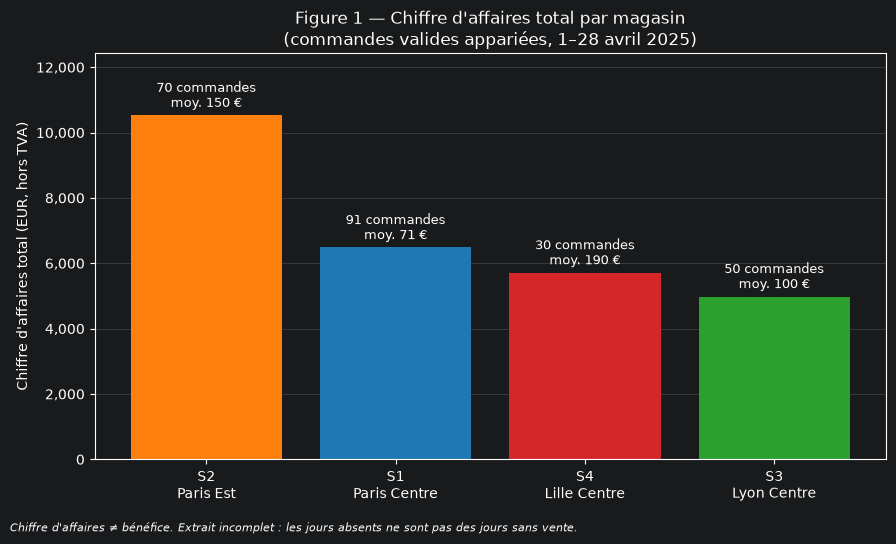

In [8]:
from matplotlib.ticker import FuncFormatter
eur = FuncFormatter(lambda v, _: f'{v:,.0f}')
COLORS = {s: plt.cm.tab10(i) for i, s in enumerate(sorted(analysis['store_id'].unique()))}

s = store_summary.sort_values('total_revenue_eur', ascending=False)
fig, ax = plt.subplots(figsize=(9, 5.4))
bars = ax.bar(s['store_id'] + '\n' + s['store_name'], s['total_revenue_eur'], color=[COLORS[x] for x in s['store_id']])
for b, n, m in zip(bars, s['orders'], s['mean_revenue_per_order_eur']):
    ax.annotate(f'{n} commandes\nmoy. {m:,.0f} €', (b.get_x() + b.get_width() / 2, b.get_height()),
                ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
ax.set_ylim(0, s['total_revenue_eur'].max() * 1.18)
ax.yaxis.set_major_formatter(eur)
ax.set_ylabel("Chiffre d'affaires total (EUR, hors TVA)")
ax.set_title("Figure 1 — Chiffre d'affaires total par magasin\n(commandes valides appariées, 1–28 avril 2025)")
ax.grid(axis='y', alpha=.3); ax.set_axisbelow(True)
fig.text(0.01, 0.005, "Chiffre d'affaires ≠ bénéfice. Extrait incomplet : les jours absents ne sont pas des jours sans vente.", fontsize=8, style='italic')
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig1_path = OUT_DIR / 'figure1_total_revenue_by_store.png'
fig.savefig(fig1_path, dpi=150, bbox_inches='tight')
plt.show()

In [9]:
second = s.iloc[1]
ratio = s.iloc[0]['total_revenue_eur'] / second['total_revenue_eur']
display(Markdown(f"""**Notre interprétation**

**Question / unité / agrégation :** total de `revenue_eur` par magasin, calculé à partir de {len(analysis)} commandes valides appariées.
**Lecture :** nous observons que {s.iloc[0]['store_id']} ({s.iloc[0]['store_name']}) est en tête avec {s.iloc[0]['total_revenue_eur']:,.0f} EUR sur {int(s.iloc[0]['orders'])} commandes, soit {ratio:.2f} fois le total de {second['store_id']} ({second['total_revenue_eur']:,.0f} EUR, {int(second['orders'])} commandes).
Les effectifs affichés rappellent que le total dépend du nombre de commandes autant que de leur montant.
**Limite :** un total additionne des commandes de natures différentes et dépend de la couverture de l'extrait ; il ne mesure ni la rentabilité ni la performance d'une « méthode de vente"."""))

**Notre interprétation**

**Question / unité / agrégation :** total de `revenue_eur` par magasin, calculé à partir de 241 commandes valides appariées.
**Lecture :** nous observons que S2 (Paris Est) est en tête avec 10,529 EUR sur 70 commandes, soit 1.62 fois le total de S1 (6,483 EUR, 91 commandes).
Les effectifs affichés rappellent que le total dépend du nombre de commandes autant que de leur montant.
**Limite :** un total additionne des commandes de natures différentes et dépend de la couverture de l'extrait ; il ne mesure ni la rentabilité ni la performance d'une « méthode de vente".


**Figure 2 — avant de coder**
- **Question :** les montants de commande sont-ils comparables d'un magasin à l'autre (centre, dispersion, valeurs atypiques) ?
- **Unité d'observation :** la commande (`revenue_eur`), sans agrégation : une valeur = une commande.
- **Agrégation :** aucune ; un boxplot par magasin avec l'effectif *n* dans l'étiquette. Les valeurs atypiques sont conservées (valides, sans preuve d'erreur).

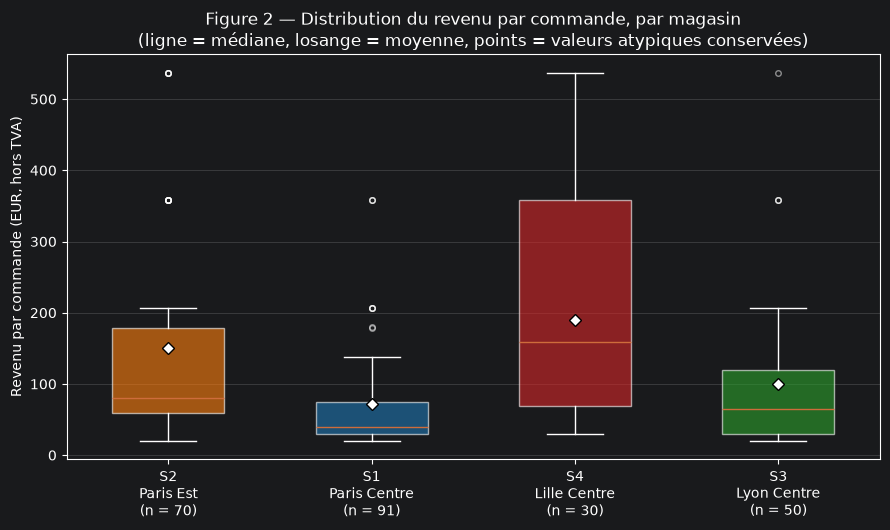

In [10]:
order_stores = list(store_summary['store_id'])
groups = [analysis.loc[analysis['store_id'] == sid, 'revenue_eur'].to_numpy() for sid in order_stores]
names = dict(zip(store_summary['store_id'], store_summary['store_name']))
fig, ax = plt.subplots(figsize=(9, 5.4))
bp = ax.boxplot(groups, patch_artist=True, showmeans=True, widths=.55,
                flierprops=dict(marker='o', markersize=4, alpha=.5),
                meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black'))
for patch, sid in zip(bp['boxes'], order_stores):
    patch.set_facecolor(COLORS[sid]); patch.set_alpha(.6)
ax.set_xticks(range(1, len(order_stores) + 1))
ax.set_xticklabels([f'{sid}\n{names[sid]}\n(n = {len(g)})' for sid, g in zip(order_stores, groups)])
ax.yaxis.set_major_formatter(eur)
ax.set_ylabel('Revenu par commande (EUR, hors TVA)')
ax.set_title('Figure 2 — Distribution du revenu par commande, par magasin\n(ligne = médiane, losange = moyenne, points = valeurs atypiques conservées)')
ax.grid(axis='y', alpha=.3); ax.set_axisbelow(True)
fig.tight_layout()
fig2_path = OUT_DIR / 'figure2_order_revenue_distribution.png'
fig.savefig(fig2_path, dpi=150, bbox_inches='tight')
plt.show()

In [11]:
q = analysis.groupby('store_id')['revenue_eur'].quantile([.25, .75]).unstack()
q['iqr'] = q[.75] - q[.25]
q['n_atypical'] = [int((analysis.loc[analysis['store_id'] == sid, 'revenue_eur'] > q.loc[sid, .75] + 1.5 * q.loc[sid, 'iqr']).sum()) for sid in q.index]
n_atyp = int(q['n_atypical'].sum())
widest = q['iqr'].idxmax()
big = analysis.loc[analysis['revenue_eur'].idxmax()]
display(Markdown(f"""**Notre interprétation**

**Question / unité :** comparer, commande par commande (unité = commande), le centre et la dispersion du revenu entre magasins ; effectifs *n* indiqués sous chaque boîte.
**Lecture :** nous constatons que la médiane par commande va de {store_summary['median_revenue_per_order_eur'].min():,.0f} à {store_summary['median_revenue_per_order_eur'].max():,.0f} EUR selon le magasin ; l'étendue interquartile est la plus grande pour {widest} ({q.loc[widest, 'iqr']:,.0f} EUR).
Au-dessus de la barrière de Tukey (Q3 + 1,5×IQR), {n_atyp} commandes ({n_atyp / len(analysis):.1%}) sont atypiques ; la plus élevée est {big['order_id']} ({big['revenue_eur']:,.0f} EUR : {int(big['quantity'])} × {big['unit_price_eur']:,.2f} EUR, catégorie {big['category']}).
Nous les **conservons** : atypique ne veut pas dire erroné, et nous n'avons aucune preuve d'erreur ; la moyenne dépasse la médiane dans {int((store_summary['mean_revenue_per_order_eur'] > store_summary['median_revenue_per_order_eur']).sum())} magasin(s) sur {len(store_summary)}, signe d'une distribution étirée vers les montants élevés.
**Limite :** un boxplot montre la distribution, pas l'origine des écarts (produit, quantité, type de client) ; les effectifs vont de {int(store_summary['orders'].min())} à {int(store_summary['orders'].max())} commandes par magasin, ce qui limite la précision des comparaisons."""))

**Notre interprétation**

**Question / unité :** comparer, commande par commande (unité = commande), le centre et la dispersion du revenu entre magasins ; effectifs *n* indiqués sous chaque boîte.
**Lecture :** nous constatons que la médiane par commande va de 40 à 158 EUR selon le magasin ; l'étendue interquartile est la plus grande pour S4 (289 EUR).
Au-dessus de la barrière de Tukey (Q3 + 1,5×IQR), 26 commandes (10.8%) sont atypiques ; la plus élevée est O0112 (537 EUR : 3 × 179.00 EUR, catégorie Screens).
Nous les **conservons** : atypique ne veut pas dire erroné, et nous n'avons aucune preuve d'erreur ; la moyenne dépasse la médiane dans 4 magasin(s) sur 4, signe d'une distribution étirée vers les montants élevés.
**Limite :** un boxplot montre la distribution, pas l'origine des écarts (produit, quantité, type de client) ; les effectifs vont de 30 à 91 commandes par magasin, ce qui limite la précision des comparaisons.


**Figure 3 — avant de coder**
- **Question :** comment le chiffre d'affaires évolue-t-il jour après jour, et quels magasins sont réellement observés chaque jour ?
- **Unité d'observation :** un magasin-jour (jour où le magasin a au moins une commande dans l'extrait).
- **Agrégation :** somme de `revenue_eur` par magasin et par date, sur le calendrier complet du 1er au 28 avril 2025. Les magasins-jours absents restent **manquants** (pas zéro).

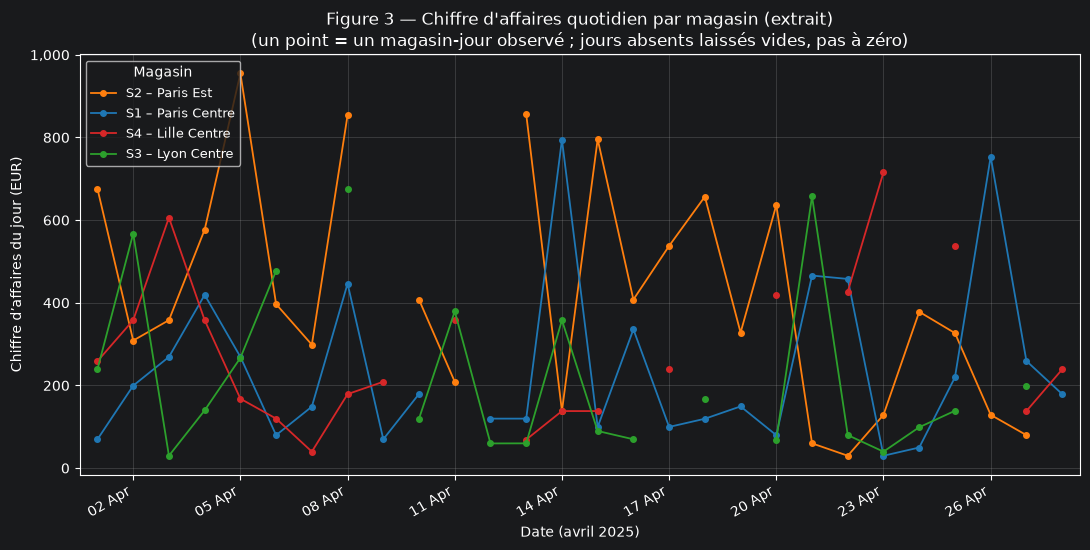

In [12]:
fig, ax = plt.subplots(figsize=(11, 5.6))
for sid in order_stores:
    ax.plot(daily_revenue.index, daily_revenue[sid], marker='o', markersize=4, linewidth=1.3,
            color=COLORS[sid], label=f'{sid} – {names[sid]}')
ax.xaxis.set_major_locator(plt.matplotlib.dates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d %b'))
ax.set_xlim(STUDY_START - pd.Timedelta(days=.5), STUDY_END + pd.Timedelta(days=.5))
ax.yaxis.set_major_formatter(eur)
ax.set_xlabel('Date (avril 2025)'); ax.set_ylabel('Chiffre d’affaires du jour (EUR)')
ax.set_title("Figure 3 — Chiffre d'affaires quotidien par magasin (extrait)\n(un point = un magasin-jour observé ; jours absents laissés vides, pas à zéro)")
ax.grid(alpha=.3); ax.legend(title='Magasin', loc='best', fontsize=9)
fig.autofmt_xdate()
fig.tight_layout()
fig3_path = OUT_DIR / 'figure3_daily_revenue_by_store.png'
fig.savefig(fig3_path, dpi=150, bbox_inches='tight')
plt.show()

In [13]:
cov = daily_revenue.notna().sum()
n_days = len(STUDY_DAYS)
peak = daily_revenue.stack().idxmax()
missing_total = int(daily_revenue.isna().sum().sum())
display(Markdown(f"""**Notre interprétation**

**Un point = un magasin-jour :** la somme du revenu des commandes valides appariées d'un magasin pour une date. Calendrier commun du 1er au 28 avril 2025 ({n_days} jours).
**Traitement des dates manquantes :** les {missing_total} magasins-jours sans commande dans l'extrait ({missing_total / daily_revenue.size:.1%} des {daily_revenue.size} possibles) sont laissés **manquants** (rupture de la ligne), pas à zéro : l'extrait est incomplet et l'absence n'est pas une fermeture ni une absence de vente.
**Lecture :** couverture en jours observés : {', '.join(f'{k} = {v}/{n_days}' for k, v in cov.items())}. Le pic quotidien est {daily_revenue.stack().max():,.0f} EUR ({peak[1]}, {peak[0]:%d/%m/%Y}).
Un pic quotidien peut venir de quelques grosses commandes seulement ; à vérifier avant de l’interpréter.
**Limite :** des couvertures différentes rendent les totaux de la Figure 1 non comparables « à jours égaux » ; on ne peut pas déduire de tendance ni de saisonnalité de 28 jours d'extrait."""))
display(Markdown("""**Pourquoi trois figures ?** La Fig. 1 répond à *combien* (total par magasin), la Fig. 2 à *comment les montants se répartissent* (valeur d'une commande typique, dispersion, valeurs atypiques) et la Fig. 3 à *quand* et *avec quelle couverture* (évolution jour par jour). Un total élevé peut venir de nombreuses petites commandes, de quelques grosses, ou de plus de jours observés : aucune figure seule ne le dit."""))

**Notre interprétation**

**Un point = un magasin-jour :** la somme du revenu des commandes valides appariées d'un magasin pour une date. Calendrier commun du 1er au 28 avril 2025 (28 jours).
**Traitement des dates manquantes :** les 18 magasins-jours sans commande dans l'extrait (16.1% des 112 possibles) sont laissés **manquants** (rupture de la ligne), pas à zéro : l'extrait est incomplet et l'absence n'est pas une fermeture ni une absence de vente.
**Lecture :** couverture en jours observés : S1 = 27/28, S2 = 25/28, S3 = 22/28, S4 = 20/28. Le pic quotidien est 955 EUR (S2, 05/04/2025).
Un pic quotidien peut venir de quelques grosses commandes seulement ; à vérifier avant de l’interpréter.
**Limite :** des couvertures différentes rendent les totaux de la Figure 1 non comparables « à jours égaux » ; on ne peut pas déduire de tendance ni de saisonnalité de 28 jours d'extrait.

**Pourquoi trois figures ?** La Fig. 1 répond à *combien* (total par magasin), la Fig. 2 à *comment les montants se répartissent* (valeur d'une commande typique, dispersion, valeurs atypiques) et la Fig. 3 à *quand* et *avec quelle couverture* (évolution jour par jour). Un total élevé peut venir de nombreuses petites commandes, de quelques grosses, ou de plus de jours observés : aucune figure seule ne le dit.

## 6. Write a decision brief
Write **six to eight sentences** addressed to the manager. Include:
- a clear answer to the original claim;
- at least two numerical results, with units and population;
- a distinction between total revenue and mean or median order revenue;
- a data-quality or integration limitation and a sample-coverage limitation;
- one plausible explanation labelled as a hypothesis;
- one proportionate next action and the extra data needed.

Avoid “Store X is best” without defining best. Do not claim causality, profitability or complete activity from this extract.

In [14]:
n_raw = len(sales_raw)
n_dup = dup_counts['sales']; n_inv = len(sales_review); n_int = len(integration_review)
excluded_share = 1 - len(analysis) / n_raw
top_cat = category_summary.iloc[0]
cmin, cmax = int(daily_revenue.notna().sum().min()), int(daily_revenue.notna().sum().max())
best_day = store_summary.loc[store_summary['revenue_per_observed_day_eur'].idxmax()]
tt, tm = top_total, top_mean
hi_cat = category_summary.loc[category_summary['mean_revenue_per_order_eur'].idxmax(), 'category']
_sh = analysis.assign(hi=analysis['category'].eq(hi_cat) * analysis['revenue_eur']).groupby('store_id')[['hi', 'revenue_eur']].sum()
_sh = 100 * _sh['hi'] / _sh['revenue_eur']
if same_store:
    hyp = (f"Hypothèse, non testée : l'avance de {tt['store_id']} pourrait refléter à la fois plus de commandes et un mix plus orienté vers la catégorie {hi_cat} "
           f"(la plus chère par commande ; {_sh[tt['store_id']]:.0f} % de son chiffre d'affaires), plutôt qu'une meilleure méthode de vente.")
else:
    if _sh[tm['store_id']] > _sh[tt['store_id']]:
        _mix = (f"ce serait cohérent avec un mix plus orienté vers la catégorie {hi_cat}, la plus chère par commande ({_sh[tm['store_id']]:.0f} % du chiffre d'affaires de {tm['store_id']} "
                f"contre {_sh[tt['store_id']]:.0f} % pour {tt['store_id']})")
    else:
        _mix = (f"le mix en catégorie la plus chère ({hi_cat} : {_sh[tm['store_id']]:.0f} % du chiffre d'affaires de {tm['store_id']} contre {_sh[tt['store_id']]:.0f} % pour {tt['store_id']}) "
                f"ne l'expliquerait pas à lui seul, les quantités ou les prix pouvant jouer aussi")
    hyp = (f"Hypothèse, non testée : l'avance de {tt['store_id']} sur le total viendrait surtout de son plus grand volume de commandes ({int(tt['orders'])} contre {int(tm['orders'])} pour {tm['store_id']}), "
           f"alors que la valeur plus élevée des commandes de {tm['store_id']} reste à expliquer : {_mix} ; aucune différence de méthode de vente n'est démontrée.")

if same_store:
    s3 = (f"En revenu par commande, {tt['store_id']} est aussi en tête ({tt['mean_revenue_per_order_eur']:,.0f} EUR en moyenne, "
          f"{tt['median_revenue_per_order_eur']:,.0f} EUR en médiane), si bien que sa première place ne tient pas qu'au volume.")
else:
    s3 = (f"En revenu moyen par commande, c'est {tm['store_id']} qui domine ({tm['mean_revenue_per_order_eur']:,.0f} EUR, médiane {tm['median_revenue_per_order_eur']:,.0f} EUR) "
          f"alors que {tt['store_id']} affiche {tt['mean_revenue_per_order_eur']:,.0f} EUR (médiane {tt['median_revenue_per_order_eur']:,.0f} EUR) : "
          f"le total additionne volume de commandes et valeur par commande, deux choses distinctes.")

brief = " ".join([
    f"Dans cet extrait (commandes terminées du 1er au 28 avril 2025), {tt['store_id']} ({tt['store_name']}) a bien le chiffre d'affaires total le plus élevé, "
    f"mais cela ne suffit pas à le déclarer « meilleur » ni à justifier de copier son approche partout.",
    f"Il totalise {tt['total_revenue_eur']:,.0f} EUR hors TVA sur {int(tt['orders'])} commandes, soit {tt['share_of_total_revenue_pct']:.1f} % des "
    f"{store_summary['total_revenue_eur'].sum():,.0f} EUR des {len(analysis)} commandes analysées.",
    s3,
    hyp,
    f"Limite de qualité : {n_raw - len(analysis)} lignes brutes sur {n_raw} ({excluded_share:.1%}) sont hors analyse ({n_dup} doublons exacts, {n_inv} lignes invalides, "
    f"{n_int} commandes valides sans magasin ou produit référencé), les commandes inhabituelles mais valides étant conservées.",
    f"Limite de couverture : l'extrait est incomplet et inégal selon les magasins ({cmin} à {cmax} jours observés sur {len(STUDY_DAYS)}) ; "
    f"un jour absent n'est pas un jour sans vente, donc les totaux ne se comparent pas à jours égaux.",
    f"Il s'agit de chiffre d'affaires et non de bénéfice : coûts, personnel, horaires et fréquentation sont inconnus, et aucune causalité n'est établie "
    f"(à titre indicatif, {best_day['store_id']} a le plus fort revenu par jour observé, {best_day['revenue_per_observed_day_eur']:,.0f} EUR).",
    "Action proportionnée : demander l'extraction complète (tous les jours, tous les magasins) avec coûts, horaires d'ouverture et fréquentation, puis comparer les magasins "
    "à jours égaux et à mix de produits comparable avant de choisir où investiguer.",
])
display(Markdown("**Note de synthèse destinée au responsable**\n\n" + brief))

**Note de synthèse destinée au responsable**

Dans cet extrait (commandes terminées du 1er au 28 avril 2025), S2 (Paris Est) a bien le chiffre d'affaires total le plus élevé, mais cela ne suffit pas à le déclarer « meilleur » ni à justifier de copier son approche partout. Il totalise 10,529 EUR hors TVA sur 70 commandes, soit 38.0 % des 27,707 EUR des 241 commandes analysées. En revenu moyen par commande, c'est S4 qui domine (190 EUR, médiane 158 EUR) alors que S2 affiche 150 EUR (médiane 80 EUR) : le total additionne volume de commandes et valeur par commande, deux choses distinctes. Hypothèse, non testée : l'avance de S2 sur le total viendrait surtout de son plus grand volume de commandes (70 contre 30 pour S4), alors que la valeur plus élevée des commandes de S4 reste à expliquer : ce serait cohérent avec un mix plus orienté vers la catégorie Screens, la plus chère par commande (78 % du chiffre d'affaires de S4 contre 66 % pour S2) ; aucune différence de méthode de vente n'est démontrée. Limite de qualité : 11 lignes brutes sur 252 (4.4%) sont hors analyse (2 doublons exacts, 7 lignes invalides, 2 commandes valides sans magasin ou produit référencé), les commandes inhabituelles mais valides étant conservées. Limite de couverture : l'extrait est incomplet et inégal selon les magasins (20 à 27 jours observés sur 28) ; un jour absent n'est pas un jour sans vente, donc les totaux ne se comparent pas à jours égaux. Il s'agit de chiffre d'affaires et non de bénéfice : coûts, personnel, horaires et fréquentation sont inconnus, et aucune causalité n'est établie (à titre indicatif, S2 a le plus fort revenu par jour observé, 421 EUR). Action proportionnée : demander l'extraction complète (tous les jours, tous les magasins) avec coûts, horaires d'ouverture et fréquentation, puis comparer les magasins à jours égaux et à mix de produits comparable avant de choisir où investiguer.

## 7. Export and reproduce
Save `store_summary.csv`, `category_summary.csv`, `reconciliation.csv`, `sales_review.csv` and `integration_review.csv` into `case_study_outputs/`. Save the three figures as PNG files. Use `index=False` for tables.

Before submitting:
- restart the kernel and run all cells from top to bottom;
- check that joins did not multiply rows and revenue totals reconcile;
- check that raw files remain unchanged;
- remove abandoned trials and explain all final decisions;
- make sure every member can explain one cleaning decision, one join control and every chart.

The deliverable is the entire completed notebook, including interpretations, not just the first figure.

In [15]:
exports = {'store_summary.csv': store_summary, 'category_summary.csv': category_summary,
           'reconciliation.csv': reconciliation, 'sales_review.csv': sales_review,
           'integration_review.csv': integration_review,
           'daily_revenue.csv': daily_revenue.reset_index()}
for fname, frame in exports.items():
    frame.to_csv(OUT_DIR / fname, index=False)


assert all(sha_ == hashlib.sha256((DATA_DIR / f).read_bytes()).hexdigest() for f, sha_ in RAW_HASHES.items()), 'Fichiers bruts modifiés !'
assert np.isclose(store_summary['total_revenue_eur'].sum(), analysis['revenue_eur'].sum())
assert len(analysis) + len(integration_review) + len(sales_review) + dup_counts['sales'] == len(sales_raw)
for p in [fig1_path, fig2_path, fig3_path]:
    assert p.exists(), p
print('Fichiers exportés dans', OUT_DIR.resolve())
for p in sorted(OUT_DIR.iterdir()):
    print(' -', p.name)
print('Fichiers bruts inchangés ✔ | jointures sans multiplication de lignes ✔ | totaux réconciliés ✔')

Fichiers exportés dans /Users/20017672/PycharmProjects/DataIntegrationCaseStudy/notebooks/case_study_outputs
 - category_summary.csv
 - daily_revenue.csv
 - figure1_total_revenue_by_store.png
 - figure2_order_revenue_distribution.png
 - figure3_daily_revenue_by_store.png
 - integration_review.csv
 - reconciliation.csv
 - sales_review.csv
 - store_summary.csv
Fichiers bruts inchangés ✔ | jointures sans multiplication de lignes ✔ | totaux réconciliés ✔


### OPTIONAL / IF TIME ALLOWS — Investigate product mix
Create a store × category table of revenue or order counts. Use a labelled heatmap or compare category shares within each store. State the denominator explicitly. Does the mix help explain different order amounts? Treat this as descriptive evidence, not a causal proof.

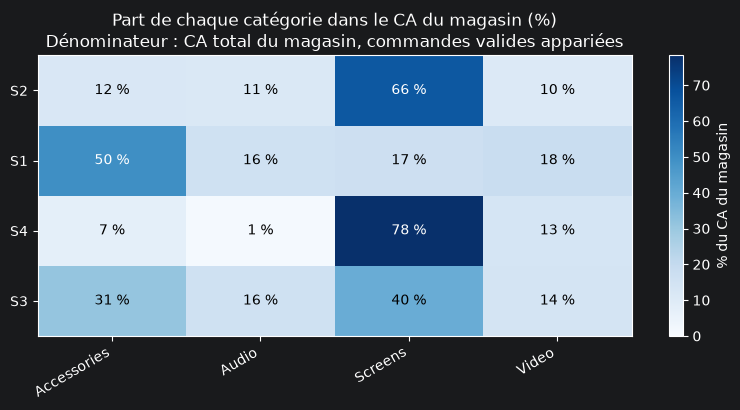

**Lecture (descriptive, pas causale) :** la catégorie la plus chère par commande est **Screens**. Sa part du chiffre d'affaires par magasin va de
17 % à 78 %, et la corrélation avec le revenu moyen par commande des magasins est de 0.98 sur 4 magasins seulement
(trop peu pour conclure). Un mix plus orienté vers Screens peut aider à expliquer des commandes plus élevées, mais ne le prouve pas.

In [16]:


mix = analysis.pivot_table(index='store_id', columns='category', values='revenue_eur', aggfunc='sum', fill_value=0)
mix = mix.loc[store_summary['store_id']]
share = 100 * mix.div(mix.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.imshow(share.values, cmap='Blues', aspect='auto', vmin=0)
ax.set_xticks(range(share.shape[1])); ax.set_xticklabels(share.columns, rotation=30, ha='right')
ax.set_yticks(range(share.shape[0])); ax.set_yticklabels(share.index)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.values[i, j]
        ax.text(j, i, f'{v:.0f} %', ha='center', va='center', color='white' if v > share.values.max() * .6 else 'black')
ax.set_title("Part de chaque catégorie dans le CA du magasin (%)\nDénominateur : CA total du magasin, commandes valides appariées")
fig.colorbar(im, ax=ax, label='% du CA du magasin')
fig.tight_layout()
fig.savefig(OUT_DIR / 'optional_category_mix_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

hi = category_summary.loc[category_summary['mean_revenue_per_order_eur'].idxmax(), 'category']
tmp = store_summary.set_index('store_id').loc[share.index]
corr = np.corrcoef(share[hi], tmp['mean_revenue_per_order_eur'])[0, 1] if len(share) > 2 else np.nan
display(Markdown(f"""**Lecture (descriptive, pas causale) :** la catégorie la plus chère par commande est **{hi}**. Sa part du chiffre d'affaires par magasin va de
{share[hi].min():.0f} % à {share[hi].max():.0f} %, et la corrélation avec le revenu moyen par commande des magasins est de {corr:.2f} sur {len(share)} magasins seulement
(trop peu pour conclure). Un mix plus orienté vers {hi} peut aider à expliquer des commandes plus élevées, mais ne le prouve pas."""))
